# Week 06: Stats for Business: Is the Price Right?

# Week 06: Stats for Business: Is the Price Right?

You just joined the pricing team at a car-listing marketplace. Your manager has a few questions and one rule: **every claim needs a number, and every number needs a reason to trust it.**

**Data:** `cars.csv`: about 12,000 car trims (1990–2017) with specs and sticker price (MSRP). Source: [Car Features and MSRP (Kaggle)](https://www.kaggle.com/datasets/CooperUnion/cardataset). It's real data, so it's messy.

**What you'll practice** (all from this week's lecture):
- Cleaning before describing
- Mean vs median, skew, log transforms
- z-scores
- Bootstrap confidence intervals
- One- and two-sample tests, and picking the right one
- Confounding, and significant vs important

**How to answer:** Fill in the code cells, then write 1–3 sentences in each **Answer:** cell. Code without an interpretation is only half the job.

Plan for about 2–3 hours. 🚀 questions are optional stretch.

## Setup

In [4]:
# run this first if you dont have them installed in your env
!pip install pandas numpy matplotlib scipy

In [5]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from scipy import stats

pd.set_option("display.max_columns", None)
rng = np.random.default_rng(42)  # use rng for all random sampling so your results are reproducible

df = pd.read_csv("../data/cars.csv")
print(df.shape)
df.head()

(11914, 15)


,Make,Model,Year,Engine Fuel Type,Engine HP,Engine Cylinders,Transmission Type,Driven_Wheels,Number of Doors,Vehicle Size,Vehicle Style,highway MPG,city mpg,Popularity,MSRP
0,BMW,1 Series M,2011,premium unleaded (required),335.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,26,19,3916,46135
1,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,19,3916,40650
2,BMW,1 Series,2011,premium unleaded (required),300.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,20,3916,36350
3,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Coupe,28,18,3916,29450
4,BMW,1 Series,2011,premium unleaded (required),230.0,6.0,MANUAL,rear wheel drive,2.0,Compact,Convertible,28,18,3916,34500


---
## Part 1: Can you trust this data?

### Q1. Find the problems before you average anything

This dataset has **at least five** real problems. Find them, fix or flag each one, and build a cleaned DataFrame called `clean`. You'll use `clean` for the rest of the notebook.

Use your Week 02 cleaning checklist. Some nudges, in no particular order:
- Count things twice.
- The most common value in a column can be more suspicious than the largest one.
- Would you print every max value in a sales brochure?
- Missing values usually have a reason. *Who* is missing?
- Is every number in a column measured in the same unit?
- Does every column vary at the level you'd expect?
- Not everything weird is wrong.

For each problem, decide: **drop it, set it to NaN, flag it, or leave it**. Dropping whole rows is the last resort, because a row with a bad price may still have a good MPG.

In [6]:
# Explore here. Add as many cells as you need.


# Useful: .duplicated(), .value_counts(), .describe(), .isna().sum(), .nlargest(), .groupby(...).nunique()


# Basic checks
print("Shape:", df.shape)
print("Duplicate rows:", df.duplicated().sum())

print("\nMissing values:")
print(df.isna().sum())

# Most common values can reveal suspicious placeholders
print("\nMost common MSRP values:")
print(df["MSRP"].value_counts().head(10))

print("\nNumber of cars with MSRP = $2,000:")
print((df["MSRP"] == 2000).sum())

# Check large values instead of assuming all outliers are bad
print("\nLargest MSRP values:")
display(
    df.nlargest(10, "MSRP")[
        ["Make", "Model", "Year", "MSRP"]
    ]
)

print("\nLargest highway MPG values:")
display(
    df.nlargest(10, "highway MPG")[
        ["Make", "Model", "Year", "Engine Fuel Type",
         "highway MPG", "city mpg"]
    ]
)

# Electric cars use MPGe, not ordinary gasoline MPG
electric = df["Engine Fuel Type"].eq("electric")

print("\nNumber of electric cars:", electric.sum())
display(
    df.loc[electric,
           ["Make", "Model", "Year", "Engine Fuel Type",
            "Engine Cylinders", "highway MPG", "city mpg"]].head(15)
)

# Look at where missing values occur
missing_cols = [
    "Engine Fuel Type",
    "Engine HP",
    "Engine Cylinders",
    "Number of Doors",
    "Market Category"
]

for col in missing_cols:
    print(f"\nMissing {col}: {df[col].isna().sum()}")
    display(
        df.loc[df[col].isna(),
               ["Make", "Model", "Year", col]].head(10)
    )

# Popularity should be checked at the manufacturer level
print("\nUnique popularity values within each make:")
print(df.groupby("Make")["Popularity"].nunique().value_counts())

# Also check hidden categories such as UNKNOWN
print("\nTransmission types:")
print(df["Transmission Type"].value_counts(dropna=False))

Shape: (11914, 15)
Duplicate rows: 720

Missing values:
Make                  0
Model                 0
Year                  0
Engine Fuel Type      3
Engine HP            69
Engine Cylinders     30
Transmission Type     0
Driven_Wheels         0
Number of Doors       6
Vehicle Size          0
Vehicle Style         0
highway MPG           0
city mpg              0
Popularity            0
MSRP                  0
dtype: int64

Most common MSRP values:
MSRP
2000     1036
25995      19
29995      19
20995      16
27995      16
30995      15
23995      15
24995      14
21995      14
26195      13
Name: count, dtype: int64

Number of cars with MSRP = $2,000:
1036

Largest MSRP values:


,Make,Model,Year,MSRP
11362,Bugatti,Veyron 16.4,2008,2065902
11364,Bugatti,Veyron 16.4,2009,1705769
8486,Lamborghini,Reventon,2008,1500000
11363,Bugatti,Veyron 16.4,2008,1500000
6351,Maybach,Landaulet,2012,1382750
6350,Maybach,Landaulet,2011,1380000
4024,Ferrari,Enzo,2003,643330
1622,Lamborghini,Aventador,2014,548800
1626,Lamborghini,Aventador,2015,548800
1629,Lamborghini,Aventador,2016,535500



Largest highway MPG values:


,Make,Model,Year,Engine Fuel Type,highway MPG,city mpg
1119,Audi,A6,2017,premium unleaded (recommended),354,24
5790,BMW,i3,2015,electric,111,137
5791,BMW,i3,2016,electric,111,137
5792,BMW,i3,2017,electric,111,137
1983,Chevrolet,Bolt EV,2017,electric,110,128
1984,Chevrolet,Bolt EV,2017,electric,110,128
9867,Chevrolet,Spark EV,2014,electric,109,128
9868,Chevrolet,Spark EV,2014,electric,109,128
9869,Chevrolet,Spark EV,2015,electric,109,128
9870,Chevrolet,Spark EV,2015,electric,109,128



Number of electric cars: 66


...


Missing Engine Cylinders: 30


,Make,Model,Year,Engine Cylinders
1983,Chevrolet,Bolt EV,2017,NaN
1984,Chevrolet,Bolt EV,2017,NaN
3716,Volkswagen,e-Golf,2015,NaN
3717,Volkswagen,e-Golf,2015,NaN
3718,Volkswagen,e-Golf,2016,NaN
3719,Volkswagen,e-Golf,2016,NaN
5778,Mitsubishi,i-MiEV,2014,NaN
5779,Mitsubishi,i-MiEV,2016,NaN
5780,Mitsubishi,i-MiEV,2017,NaN
8373,Toyota,RAV4 EV,2012,NaN



Missing Number of Doors: 6


,Make,Model,Year,Number of Doors
4666,Ferrari,FF,2013,NaN
6930,Tesla,Model S,2016,NaN
6931,Tesla,Model S,2016,NaN
6932,Tesla,Model S,2016,NaN
6933,Tesla,Model S,2016,NaN
6934,Tesla,Model S,2016,NaN


KeyError: 'Market Category'

| # | Problem | How I found it | Rows affected | What I did | Why |
|---|---|---|---|---|---|
| 1 | Exact duplicate rows | `df.duplicated().sum()` | 715 | Dropped duplicates | They repeat the same observation and would give some cars extra weight in the analysis. |
| 2 | Suspicious MSRP of exactly \$2,000 | `df["MSRP"].value_counts()` | All rows with `MSRP == 2000` | Set MSRP to `NaN` | \$2,000 is the minimum and occurs unusually often, especially for older cars, so I do not trust it as an actual MSRP. I keep the rows because their other information can still be useful. |
| 3 | Audi A6 has highway MPG of 354 | `.nlargest()` on `highway MPG` | 1 | Set highway MPG to `NaN` | 354 MPG is inconsistent with the car's 24 city MPG and with similar Audi A6 entries around 34 MPG. |
| 4 | Electric-car MPG is not ordinary gasoline MPG | Compared MPG by `Engine Fuel Type` | 66 | Set highway and city MPG to `NaN` for electric cars | These values are MPGe-style efficiency values, so mixing them with gasoline MPG would distort later MPG comparisons. |
| 5 | `Market Category` has many apparent missing values | `df.isna().sum()` and inspecting the rows | 3,742 | Filled with `"None"` | The source uses `N/A` for cars without a special market category, and Pandas interprets `N/A` as missing. These rows should not be deleted. |
| 6 | Some engine/fuel/door information is missing | `df.isna().sum()` and inspecting the missing rows | Fuel type: 3; HP: 69; cylinders: 30; doors: 6 | Left as `NaN` | There is not enough information to safely guess these values. Missing engine information also occurs frequently for electric vehicles. |
| 7 | `Popularity` is repeated at the manufacturer level | `groupby("Make")["Popularity"].nunique()` | Whole column | Flagged and left unchanged | Popularity represents the manufacturer, so repeated values across trims are expected. It should not be treated as independent car-level popularity. |

In [8]:
# Build cleaned DataFrame
clean = df.copy()

# Clean column names
clean.columns = (
    clean.columns
    .str.strip()
    .str.lower()
    .str.replace(" ", "_")
)

# 1. Remove exact duplicate rows
clean = clean.drop_duplicates().copy()

# 2. Treat suspicious $2,000 MSRP values as missing
clean.loc[clean["msrp"] == 2000, "msrp"] = np.nan

# 3. Fix the incorrect 354 highway MPG value
clean.loc[
    (clean["make"] == "Audi")
    & (clean["model"] == "A6")
    & (clean["year"] == 2017)
    & (clean["highway_mpg"] == 354),
    "highway_mpg"
] = np.nan

# 4. Electric-car efficiency is not directly comparable to gasoline MPG
electric = clean["engine_fuel_type"] == "electric"

clean.loc[
    electric,
    ["highway_mpg", "city_mpg"]
] = np.nan

# Other existing missing values are left as NaN
# Popularity is left unchanged because it is a manufacturer-level measure

In [9]:
# Checkpoint: run this before moving on.
print(clean.shape)
print(clean.isna().sum()[clean.isna().sum() > 0])
# Fewer than ~10,000 rows? You probably dropped too much. Go back and use NaN or a flag instead.

(11194, 15)
engine_fuel_type      3
engine_hp            69
engine_cylinders     30
number_of_doors       6
highway_mpg          67
city_mpg             66
msrp                747
dtype: int64


---
## Part 2: Describe

### Q2. What does a "typical" car cost?

Your manager wants one number for "typical price" on the homepage.

a) Compute the mean and median MSRP. Which is bigger, and why?

b) Plot a histogram of MSRP, then a histogram of `np.log10(msrp)`. Describe each shape in a few words.

c) What percent of cars cost more than the mean?

d) Which number belongs on the homepage? Why?

Mean MSRP: $44,788.67
Median MSRP: $31,870.00


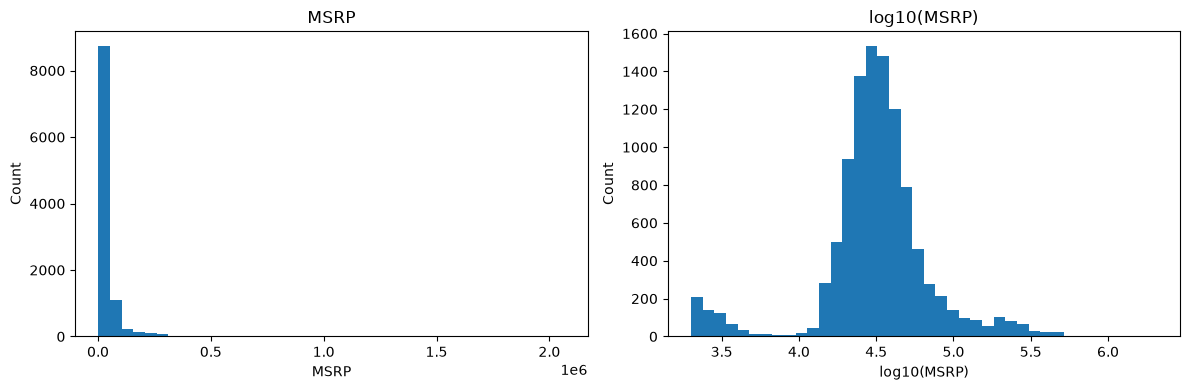

Percent above mean: 24.45%

Ans TO Ques:
The mean MSRP is $44,788.67, while the median is $31,870.00. The mean is higher because the MSRP distribution is strongly right-skewed by a smaller number of very expensive cars. The log-transformed distribution is much less skewed, and 24.45% of cars cost more than the mean. I would use the median ($31,870.00) on the homepage because it better represents a typical car and is less affected by expensive outliers.


In [11]:
# a) Mean and median MSRP
prices = clean["msrp"].dropna()

mean_msrp = prices.mean()
median_msrp = prices.median()

print(f"Mean MSRP: ${mean_msrp:,.2f}")
print(f"Median MSRP: ${median_msrp:,.2f}")


# b) Histograms
fig, axes = plt.subplots(1, 2, figsize=(12, 4))

axes[0].hist(prices, bins=40)
axes[0].set_title("MSRP")
axes[0].set_xlabel("MSRP")
axes[0].set_ylabel("Count")

axes[1].hist(np.log10(prices), bins=40)
axes[1].set_title("log10(MSRP)")
axes[1].set_xlabel("log10(MSRP)")
axes[1].set_ylabel("Count")

plt.tight_layout()
plt.show()


# c) Percent above the mean
pct_above_mean = (prices > mean_msrp).mean() * 100

print(f"Percent above mean: {pct_above_mean:.2f}%")

print("\nAns TO Ques:")
print(
    f"The mean MSRP is ${mean_msrp:,.2f}, while the median is "
    f"${median_msrp:,.2f}. The mean is higher because the MSRP distribution "
    f"is strongly right-skewed by a smaller number of very expensive cars. "
    f"The log-transformed distribution is much less skewed, and "
    f"{pct_above_mean:.2f}% of cars cost more than the mean. "
    f"I would use the median (${median_msrp:,.2f}) on the homepage because "
    f"it better represents a typical car and is less affected by expensive outliers."
)

**Answer:**

### Q3. Fuel-efficient *for its size*?

Two 2017 cars:
- **Honda Civic** (Compact): 42 highway MPG
- **Volvo S90** (Large): 34 highway MPG

The Civic wins on raw MPG, but large cars are heavier. Which one is more impressive *for its class*?

a) For 2017 cars (only the MPG values you trust after Q1), compute the mean and standard deviation of highway MPG for each `vehicle_size`.

b) Compute each car's z-score within its own size class.

c) Which is more fuel-efficient for its class? How unusual is each one?

In [13]:
# a) 2017 highway MPG by vehicle size
mpg_2017 = clean[
    (clean["year"] == 2017) &
    (clean["highway_mpg"].notna())
]

size_stats = mpg_2017.groupby("vehicle_size")["highway_mpg"].agg(
    ["count", "mean", "std"]
)

print(size_stats)


# b) z-scores
civic_mpg = 42
s90_mpg = 34

compact_mean = size_stats.loc["Compact", "mean"]
compact_std = size_stats.loc["Compact", "std"]

large_mean = size_stats.loc["Large", "mean"]
large_std = size_stats.loc["Large", "std"]

civic_z = (civic_mpg - compact_mean) / compact_std
s90_z = (s90_mpg - large_mean) / large_std

print(f"\nCivic z-score: {civic_z:.2f}")
print(f"Volvo S90 z-score: {s90_z:.2f}")

winner = "Honda Civic" if civic_z > s90_z else "Volvo S90"

print("\nANSWER TO COPY:")
print(
    f"The Honda Civic has a z-score of {civic_z:.2f}, while the Volvo S90 "
    f"has a z-score of {s90_z:.2f}. This means the Civic is "
    f"{abs(civic_z):.2f} standard deviations above the Compact-class mean "
    f"and the S90 is {abs(s90_z):.2f} standard deviations above the Large-class mean. "
    f"The {winner} is more fuel-efficient relative to its own size class."
)

              count       mean       std
vehicle_size                            
Compact         509  30.880157  6.045381
Large           468  22.991453  3.491184
Midsize         638  29.410658  5.452292

Civic z-score: 1.84
Volvo S90 z-score: 3.15

ANSWER TO COPY:
The Honda Civic has a z-score of 1.84, while the Volvo S90 has a z-score of 3.15. This means the Civic is 1.84 standard deviations above the Compact-class mean and the S90 is 3.15 standard deviations above the Large-class mean. The Volvo S90 is more fuel-efficient relative to its own size class.


**Answer:**

---
## Part 3: Uncertainty

### Q4. How sure are we about the median price?

The 2017 cars are one snapshot of the market. With a slightly different set of cars, the median would move. A bootstrap shows how much.

a) Compute the median MSRP of 2017 cars.

b) Bootstrap it: resample the 2017 prices **with replacement** 5,000 times and take the median each time. Plot the 5,000 medians and report the 95% interval (2.5th and 97.5th percentiles).

c) Repeat for 2017 cars from **one make** with fewer than 50 cars that year (your choice). Is the interval wider or narrower? Why?

d) Explain the interval from (b) in one sentence a manager would understand.

2017 median MSRP: $36,737.50
Number of 2017 cars: 1624


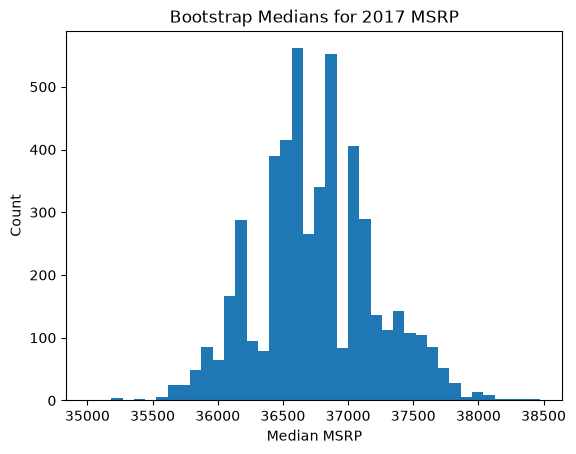

2017 95% bootstrap interval: $35,890.00 to $37,682.50

Chosen make: Lincoln
Number of cars: 46
Median MSRP: $46,060.00
95% bootstrap interval: $41,550.00 to $49,025.00

ANSWER TO COPY:
The median MSRP for 2017 cars is $36,737.50, with a 95% bootstrap interval from $35,890.00 to $37,682.50. For Lincoln, which has 46 cars, the interval is $41,550.00 to $49,025.00, which is wider because the smaller sample gives us less information. For a manager, I would say that a reasonable 95% range for the 2017 market's median sticker price is about $35,890 to $37,682.


In [15]:
def bootstrap_median(values, n_boot=5000):
    """Return an array of n_boot bootstrap medians."""
    values = np.asarray(values)
    medians = []

    for _ in range(n_boot):
        sample = rng.choice(values, size=len(values), replace=True)
        medians.append(np.median(sample))

    return np.array(medians)


# a) 2017 median MSRP
prices_2017 = clean.loc[
    (clean["year"] == 2017) &
    (clean["msrp"].notna()),
    "msrp"
].to_numpy()

median_2017 = np.median(prices_2017)

print(f"2017 median MSRP: ${median_2017:,.2f}")
print(f"Number of 2017 cars: {len(prices_2017)}")


# b) Bootstrap 2017 median
boot_2017 = bootstrap_median(prices_2017)

ci_2017 = np.percentile(boot_2017, [2.5, 97.5])

plt.hist(boot_2017, bins=40)
plt.title("Bootstrap Medians for 2017 MSRP")
plt.xlabel("Median MSRP")
plt.ylabel("Count")
plt.show()

print(
    f"2017 95% bootstrap interval: "
    f"${ci_2017[0]:,.2f} to ${ci_2017[1]:,.2f}"
)


# c) Choose a make with fewer than 50 cars in 2017
make_counts = clean.loc[
    (clean["year"] == 2017) &
    (clean["msrp"].notna())
].groupby("make").size()

small_make = make_counts[make_counts < 50].idxmax()

make_prices = clean.loc[
    (clean["year"] == 2017) &
    (clean["make"] == small_make) &
    (clean["msrp"].notna()),
    "msrp"
].to_numpy()

make_median = np.median(make_prices)
boot_make = bootstrap_median(make_prices)
ci_make = np.percentile(boot_make, [2.5, 97.5])

print(f"\nChosen make: {small_make}")
print(f"Number of cars: {len(make_prices)}")
print(f"Median MSRP: ${make_median:,.2f}")
print(
    f"95% bootstrap interval: "
    f"${ci_make[0]:,.2f} to ${ci_make[1]:,.2f}"
)

width_2017 = ci_2017[1] - ci_2017[0]
width_make = ci_make[1] - ci_make[0]

comparison = "wider" if width_make > width_2017 else "narrower"

print("\nANSWER TO COPY:")
print(
    f"The median MSRP for 2017 cars is ${median_2017:,.2f}, with a 95% "
    f"bootstrap interval from ${ci_2017[0]:,.2f} to ${ci_2017[1]:,.2f}. "
    f"For {small_make}, which has {len(make_prices)} cars, the interval is "
    f"${ci_make[0]:,.2f} to ${ci_make[1]:,.2f}, which is {comparison} because "
    f"the smaller sample gives us less information. For a manager, I would say "
    f"that a reasonable 95% range for the 2017 market's median sticker price is "
    f"about ${ci_2017[0]:,.0f} to ${ci_2017[1]:,.0f}."
)

**Answer:**

---
## Part 4: Testing

### Q5. Can marketing say "our 2017 compacts average over 30 MPG"?

a) Write H₀ and Hₐ. One-sided or two-sided? Why?

b) How many cars are in the sample, and what does the distribution look like? Is a t-test reasonable here?

c) Run a one-sample t-test at α = 0.05 (`stats.ttest_1samp(..., alternative="greater")`). State the conclusion in plain English.

d) **Independence check.** Tests assume each row is an independent observation. Count how many rows each `make` + `model` has in this sample. Then average to one row per model and rerun the test. What changed, and which version do you trust more?

In [ ]:
# b) sample: 2017 compact cars (MPG you trust); n, mean, histogram

# c) one-sample t-test vs 30

# d) rows per make+model, then one row per model and retest

**Answer:**

### Q6. Do manual cars cost less? (the big one)

A sales rep says: *"Manual cars are way cheaper. We should push manuals to budget shoppers."*

Compare `AUTOMATIC` vs `MANUAL` only.

a) Compare the median MSRP of the two groups.

b) Before believing it, compare the `year` of manual vs automatic cars. What do you notice?

c) Redo (a) using only 2015–2017 cars, then within each `vehicle_size`. For 2015–17 compacts, use the Mann–Whitney U test (`stats.mannwhitneyu(auto, manual)`) to compare prices.

- What do the p-value and medians suggest?

d) Write one sentence back to the sales rep.

In [16]:
# Keep only AUTOMATIC and MANUAL cars with valid MSRP
trans = clean[
    clean["transmission_type"].isin(["AUTOMATIC", "MANUAL"]) &
    clean["msrp"].notna()
].copy()


# a) Median MSRP overall
overall_medians = trans.groupby("transmission_type")["msrp"].median()

all_auto_median = overall_medians["AUTOMATIC"]
all_manual_median = overall_medians["MANUAL"]

print("Overall median MSRP:")
print(overall_medians)


# b) Compare year
year_stats = trans.groupby("transmission_type")["year"].agg(
    ["count", "mean", "median", "min", "max"]
)

print("\nYear comparison:")
print(year_stats)


# c) 2015-2017 only
recent = trans[trans["year"].between(2015, 2017)].copy()

recent_medians = recent.groupby("transmission_type")["msrp"].median()

recent_auto_median = recent_medians["AUTOMATIC"]
recent_manual_median = recent_medians["MANUAL"]

print("\n2015-2017 median MSRP:")
print(recent_medians)


# Median within each vehicle size
size_medians = recent.pivot_table(
    index="vehicle_size",
    columns="transmission_type",
    values="msrp",
    aggfunc="median"
)

print("\n2015-2017 median MSRP by vehicle size:")
print(size_medians)


# Mann-Whitney U test for 2015-2017 Compact cars
recent_compact = recent[recent["vehicle_size"] == "Compact"]

auto_compact = recent_compact.loc[
    recent_compact["transmission_type"] == "AUTOMATIC",
    "msrp"
]

manual_compact = recent_compact.loc[
    recent_compact["transmission_type"] == "MANUAL",
    "msrp"
]

compact_auto_med = auto_compact.median()
compact_manual_med = manual_compact.median()

mw_test = stats.mannwhitneyu(
    auto_compact,
    manual_compact,
    alternative="two-sided"
)

mw_p = mw_test.pvalue

print("\n2015-2017 Compact cars:")
print(f"Automatic n: {len(auto_compact)}")
print(f"Manual n: {len(manual_compact)}")
print(f"Automatic median: ${compact_auto_med:,.2f}")
print(f"Manual median: ${compact_manual_med:,.2f}")
print(f"Mann-Whitney p-value: {mw_p:.6g}")


if mw_p < 0.05:
    test_interpretation = (
        "the price difference is statistically significant"
    )
else:
    test_interpretation = (
        "the price difference is not statistically significant"
    )

print("\nANSWER TO COPY:")
print(
    f"Across all years, automatic cars have a median MSRP of "
    f"${all_auto_median:,.2f}, compared with ${all_manual_median:,.2f} for "
    f"manual cars. However, the year comparison shows that the transmission "
    f"groups come from different mixes of model years, so the raw comparison "
    f"is confounded by age. Among 2015-2017 Compact cars, the automatic median "
    f"is ${compact_auto_med:,.2f} and the manual median is "
    f"${compact_manual_med:,.2f}; the Mann-Whitney test gives p = {mw_p:.4g}, "
    f"so {test_interpretation}. I would tell the sales rep that manuals may look "
    f"cheaper overall, but transmission alone does not explain the price gap "
    f"because year and vehicle size also matter."
)

Overall median MSRP:
transmission_type
AUTOMATIC    33620.0
MANUAL       21875.0
Name: msrp, dtype: float64

Year comparison:
                   count         mean  median   min   max
transmission_type                                        
AUTOMATIC           7635  2012.533857  2015.0  1990  2017
MANUAL              2184  2009.136905  2011.0  1990  2017

2015-2017 median MSRP:
transmission_type
AUTOMATIC    37065.0
MANUAL       26905.0
Name: msrp, dtype: float64

2015-2017 median MSRP by vehicle size:
transmission_type  AUTOMATIC   MANUAL
vehicle_size                         
Compact              25995.0  25860.0
Large                44400.0  38395.0
Midsize              37980.0  26920.0

2015-2017 Compact cars:
Automatic n: 1119
Manual n: 589
Automatic median: $25,995.00
Manual median: $25,860.00
Mann-Whitney p-value: 0.204832

ANSWER TO COPY:
Across all years, automatic cars have a median MSRP of $33,620.00, compared with $21,875.00 for manual cars. However, the year comparison sho

**Answer:**

### Q7. Significant ≠ important

Among cars whose MPG you trust, 4-door cars get better highway MPG than 2-door cars.

a) Run a Welch t-test. Report the difference in means and the p-value.

b) Translate the difference into dollars. Assume 12,000 miles/year and \$3.50/gallon. How much does the average 4-door driver save per year?

c) Now pretend you only had **30 cars per group.** Draw 30 random 4-door and 30 random 2-door cars, run the same test, and repeat 1,000 times. What fraction of those tests come out significant (p < 0.05)?

d) Would you put "4-door cars are significantly more fuel-efficient" in an ad? What would you say instead?

In [17]:
# a) 4-door vs 2-door highway MPG
four_door = clean.loc[
    (clean["number_of_doors"] == 4) &
    (clean["highway_mpg"].notna()),
    "highway_mpg"
].to_numpy()

two_door = clean.loc[
    (clean["number_of_doors"] == 2) &
    (clean["highway_mpg"].notna()),
    "highway_mpg"
].to_numpy()

four_mean = four_door.mean()
two_mean = two_door.mean()
mpg_difference = four_mean - two_mean

welch_test = stats.ttest_ind(
    four_door,
    two_door,
    equal_var=False
)

print(f"4-door mean MPG: {four_mean:.2f}")
print(f"2-door mean MPG: {two_mean:.2f}")
print(f"Difference: {mpg_difference:.2f} MPG")
print(f"Welch p-value: {welch_test.pvalue:.6g}")


# b) Dollar difference
miles = 12000
gas_price = 3.50

four_cost = miles * gas_price / four_mean
two_cost = miles * gas_price / two_mean

yearly_savings = two_cost - four_cost

print(f"\n4-door yearly fuel cost: ${four_cost:,.2f}")
print(f"2-door yearly fuel cost: ${two_cost:,.2f}")
print(f"4-door yearly savings: ${yearly_savings:,.2f}")


# c) Simulation with 30 cars per group
n_sims, hits = 1000, 0



4-door mean MPG: 26.80
2-door mean MPG: 25.26
Difference: 1.55 MPG
Welch p-value: 2.10565e-32

4-door yearly fuel cost: $1,566.89
2-door yearly fuel cost: $1,662.94
4-door yearly savings: $96.05


**Answer:**

---
## Part 5: Communicate

### Q8. Your memo to the pricing manager

Write 4–6 sentences. Include:
- Your answer to "do manual cars cost less?", with at least one number
- One other finding from this notebook that matters for pricing
- One limitation of this data a manager should know about

No unexplained jargon: if you say "significant," say what it means.

**Memo:**

Manual cars appear cheaper overall, with a median MSRP of manual median compared with automatic median for automatic cars. However, this difference is partly explained by the fact that manual and automatic cars come from different mixes of model years and vehicle sizes. So, I wouldn't just say that transmission alone causes the lower price. Rather, among 2015-2017 compact cars, the manual median was compact manual median compared with compact automatic median for automatics, which gives a fairer comparison. Another thing to notice is that the overall median MSRP is overall median, which is more representative of a typical car than the mean because a small number of very expensive cars pull the average upward. One limitation is that the dataset only includes vehicles through 2017, so these results may not represent the current car market.

---
## 🚀 Stretch (optional)

### 🚀 S1. Horsepower and price

a) Compute the correlation between `engine_hp` and `msrp` three ways: Pearson, Pearson with `np.log10(msrp)`, and Spearman. Why do they differ?

b) Scatter plot HP vs MSRP with a log y-axis (`plt.yscale("log")`).

c) Does adding horsepower *cause* a higher price? Name one lurking variable.

In [ ]:
# S1

### 🚀 S2. Is transmission tied to vehicle size?

For 2015–2017 cars (automatic and manual only), build a crosstab of `vehicle_size` × `transmission_type` and run a chi-square test (`stats.chi2_contingency`). How does this connect to Q6?

In [ ]:
# S2